## ML project 2


In [81]:
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

### Our target variable is the heart disease

### EDA

In [82]:
df = pd.read_csv('heart.csv')
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


In [83]:
df.shape

(918, 12)

In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [85]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [86]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='HeartDisease'>

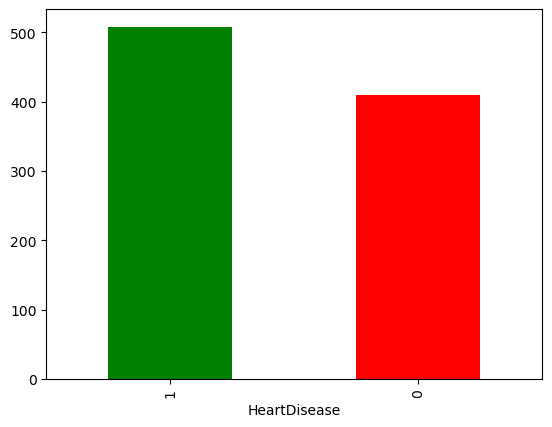

In [87]:
df['HeartDisease'].value_counts().plot(kind='bar', color=['green', 'red'])

In [88]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

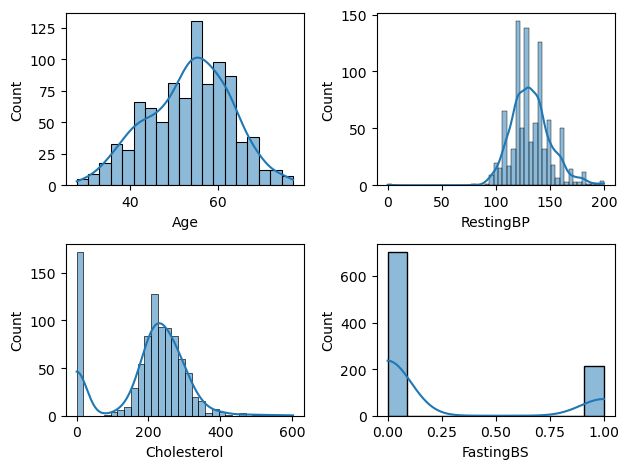

In [89]:
# we can also define a plotting function to plot the distribution of the features in the dataset.
def plott(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var], kde = True)

plott('Age', 1)
plott('RestingBP', 2)
plott('Cholesterol', 3)
plott('FastingBS', 4)
plt.tight_layout()


In [90]:
df['Cholesterol'].value_counts()

Cholesterol
0      172
254     11
220     10
223     10
204      9
      ... 
353      1
278      1
157      1
176      1
131      1
Name: count, Length: 222, dtype: int64

In [91]:
df['RestingBP'].value_counts()

RestingBP
120    132
130    118
140    107
110     58
150     55
      ... 
101      1
117      1
192      1
129      1
164      1
Name: count, Length: 67, dtype: int64

#### we see that there are people with 0 cholesterol and resting BP of 1. This is never percieved. We will fill this 0 with mean cholesterol and BP values.

In [92]:
# calculate mean cholesterol but for the people with cholesterol greater than 0.
ch_mean = df.loc[df['Cholesterol'] != 0, 'Cholesterol'].mean()
df['Cholesterol'] = df['Cholesterol'].replace(0, ch_mean).round(2)

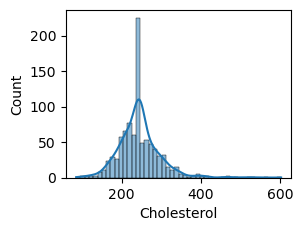

In [93]:
plott('Cholesterol', 1)

In [94]:
# calculate mean resting blood pressure but for the people with cholesterol greater than 0.
rBP_mean = df.loc[df['RestingBP'] != 0, 'RestingBP'].mean()
df['RestingBP'] = df['RestingBP'].replace(0, rBP_mean).round(2)

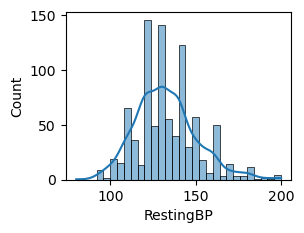

In [95]:
plott('RestingBP', 1)

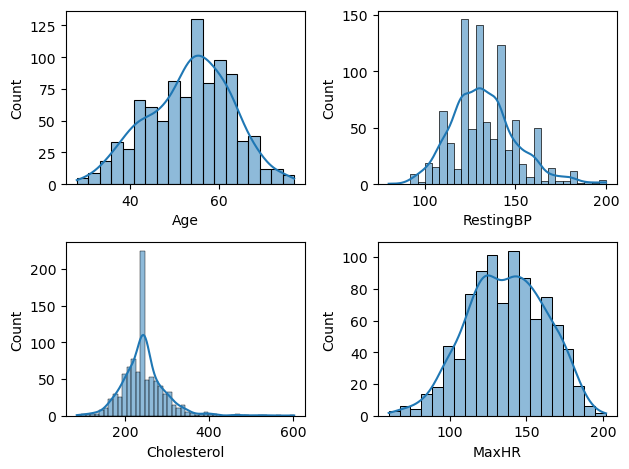

In [96]:
plott('Age',1)
plott('RestingBP',2)
plott('Cholesterol',3)
plott('MaxHR',4)
plt.tight_layout()

<Axes: xlabel='Sex', ylabel='count'>

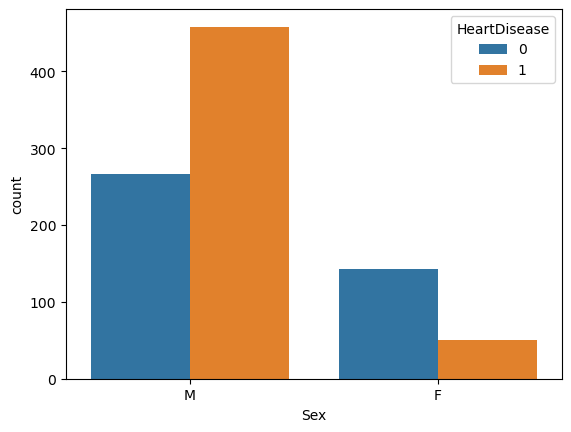

In [97]:
sns.countplot(x=df['Sex'], hue = df['HeartDisease'])

In [98]:
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110.0,264.0,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144.0,193.0,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130.0,131.0,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130.0,236.0,0,LVH,174,N,0.0,Flat,1


<Axes: >

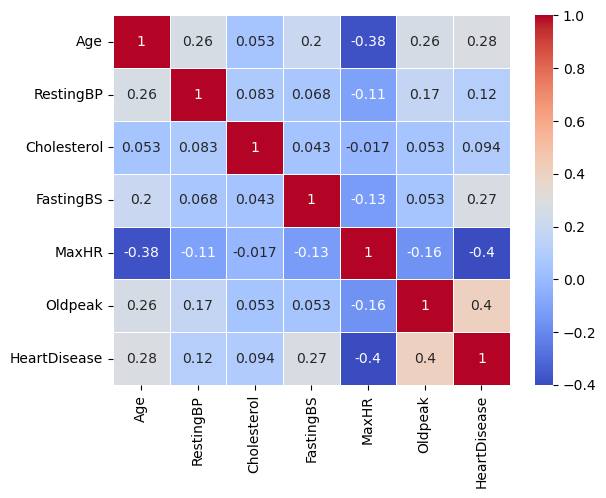

In [99]:
sns.heatmap(df.corr(numeric_only=True), annot = True, cmap = 'coolwarm', linewidths = 0.5)

In [100]:
df_clean = df.drop(columns = ['HeartDisease'], axis=1)
y = df['HeartDisease']

In [111]:
df_clean = pd.get_dummies(df, columns = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'], drop_first = True)
df_clean


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140.0,289.0,0,172,0.0,0,True,True,False,False,True,False,False,False,True
1,49,160.0,180.0,0,156,1.0,1,False,False,True,False,True,False,False,True,False
2,37,130.0,283.0,0,98,0.0,0,True,True,False,False,False,True,False,False,True
3,48,138.0,214.0,0,108,1.5,1,False,False,False,False,True,False,True,True,False
4,54,150.0,195.0,0,122,0.0,0,True,False,True,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110.0,264.0,0,132,1.2,1,True,False,False,True,True,False,False,True,False
914,68,144.0,193.0,1,141,3.4,1,True,False,False,False,True,False,False,True,False
915,57,130.0,131.0,0,115,1.2,1,True,False,False,False,True,False,True,True,False
916,57,130.0,236.0,0,174,0.0,1,False,True,False,False,False,False,False,True,False


In [113]:
df_clean = df_clean.astype(int)
df_clean.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0,0,1,1,0,0,1,0,0,0,1
1,49,160,180,0,156,1,1,0,0,1,0,1,0,0,1,0
2,37,130,283,0,98,0,0,1,1,0,0,0,1,0,0,1
3,48,138,214,0,108,1,1,0,0,0,0,1,0,1,1,0
4,54,150,195,0,122,0,0,1,0,1,0,1,0,0,0,1


In [114]:
# applying standard scalar to the dataset to scale the features to a standard normal distribution.
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [115]:
columns = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR']
df_clean[columns] = scaler.fit_transform(df_clean[columns])
df_clean.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0.414885,0.834754,0,1.382928,0,0,1,1,0,0,1,0,0,0,1
1,-0.478484,1.527224,-1.210675,0,0.754157,1,1,0,0,1,0,1,0,0,1,0
2,-1.751359,-0.141284,0.722161,0,-1.525138,0,0,1,1,0,0,0,1,0,0,1
3,-0.584556,0.303651,-0.572651,0,-1.132156,1,1,0,0,0,0,1,0,1,1,0
4,0.051881,0.971054,-0.929194,0,-0.581981,0,0,1,0,1,0,1,0,0,0,1


In [131]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
x_train, x_test, y_train, y_test = train_test_split(df_clean, y, test_size = 0.20, random_state = 42)

In [132]:
model = LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

In [133]:
y_pred = model.predict(x_test)
y_pred

array([ 6.32915344e-16,  1.00000000e+00,  1.00000000e+00,  1.00000000e+00,
       -2.39655386e-15,  1.00000000e+00,  1.00000000e+00, -1.67916753e-15,
        1.00000000e+00,  1.00000000e+00, -2.63056217e-15, -1.70102497e-15,
        5.10004512e-16, -2.29142564e-15,  1.00000000e+00,  1.00000000e+00,
        1.53793654e-15,  1.00000000e+00,  1.00000000e+00, -5.60653265e-18,
        1.00000000e+00,  2.99344082e-15, -8.98869326e-16, -7.13856945e-16,
        1.00000000e+00,  1.00000000e+00, -1.96280024e-15,  1.00000000e+00,
       -2.25182996e-15, -1.87790180e-15,  1.00000000e+00,  1.00000000e+00,
       -3.08975307e-16,  1.00000000e+00,  1.00000000e+00, -1.20862974e-15,
        1.00000000e+00, -1.06174154e-15,  1.00000000e+00,  1.00000000e+00,
        1.00000000e+00,  1.00000000e+00,  1.00000000e+00,  3.70756894e-16,
        3.41323930e-15, -2.65363847e-16,  1.00000000e+00,  1.00000000e+00,
        1.00000000e+00,  1.16322688e-16,  1.00000000e+00, -1.63129697e-15,
        1.00000000e+00,  

In [134]:
y_test

668    0
30     1
377    1
535    1
807    0
      ..
211    1
745    1
584    1
878    0
451    1
Name: HeartDisease, Length: 184, dtype: int64

In [135]:
# r2 score
r2 = r2_score(y_test, y_pred)
r2

1.0

In [136]:
n = x_test.shape[0]
p = x_test.shape[1]
adjusted_r2 = 1 - ((1-r2)*(n-1))/(n-p-1)
adjusted_r2

1.0

In [137]:
x_train1, x_test1, y_train1, y_test1 = train_test_split(df_clean, y, test_size = 0.50, random_state = 42)

In [138]:
model1 = LinearRegression()
model1.fit(x_train1, y_train1)

LinearRegression()

In [139]:
y_pred1 = model1.predict(x_test1)

In [140]:
r2_1 = r2_score(y_test1, y_pred1)
r2_1

1.0